<small>

### Library & Constant Values

</small>

In [1]:
from torchvision import datasets, transforms as T
import torch
import random
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision.models import regnet_y_400mf, RegNet_X_400MF_Weights
import torch.nn as nn
import time

In [2]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
TRAIN_DIR = "../dataset/imagenette/train"
VAL_DIR = "../dataset/imagenette/val"
CLASS_NUM = 10
EPOCH = 50

<small>

### Data Acquisition & Data Preparation

</small>

In [3]:
train_transform = T.Compose([
    T.Resize(160),
    T.RandomCrop(160, padding=4),
    T.RandomHorizontalFlip(),
    T.ColorJitter(brightness=0.1),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.75, scale=(0.02, 0.1), value=0),
])

val_transform = T.Compose([
    T.Resize(160),
    T.CenterCrop(160),
    T.ToTensor(),
    T.Normalize(MEAN, STD)
])

In [4]:
train_ds = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
val_ds = datasets.ImageFolder(VAL_DIR, transform=val_transform)

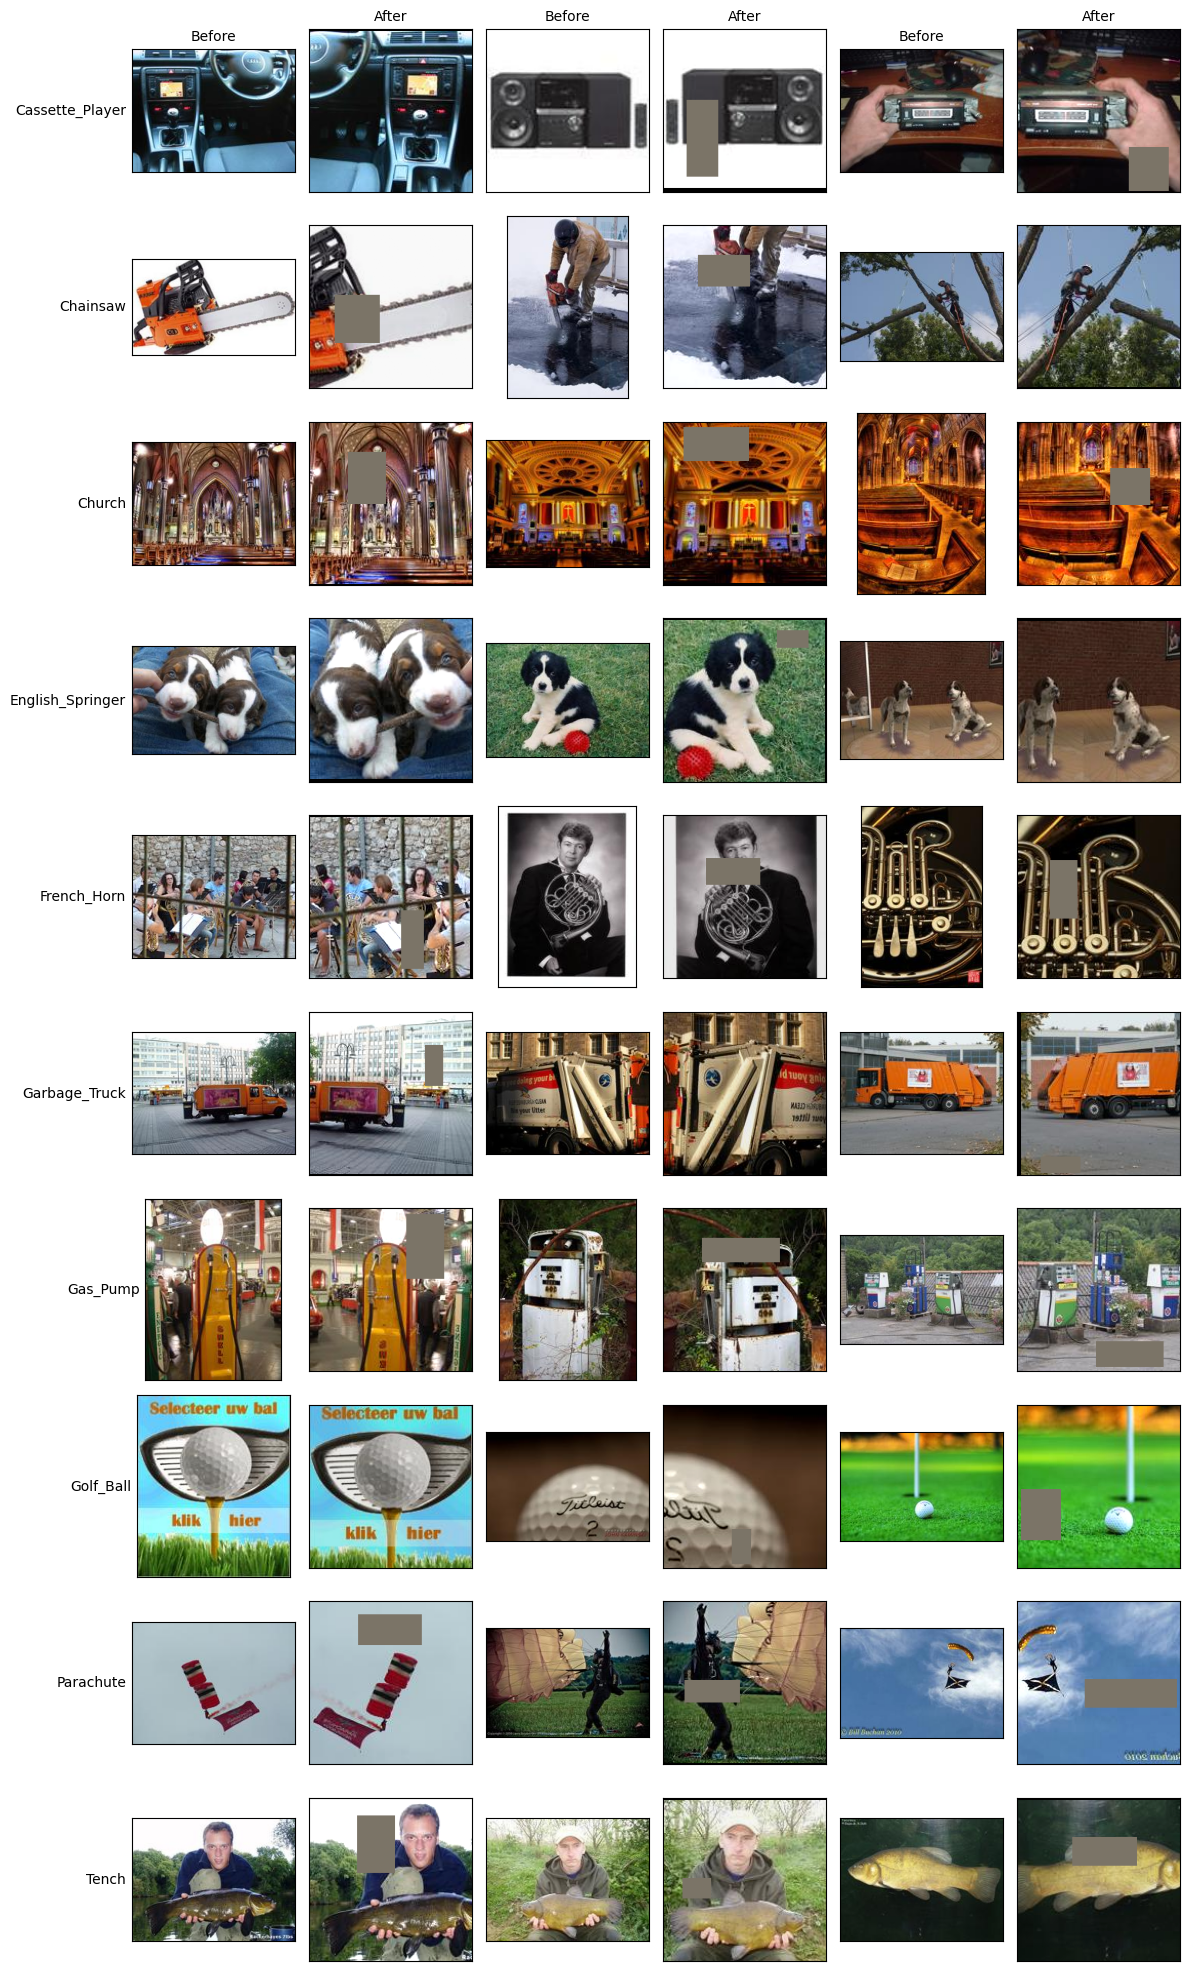

In [5]:
raw_train_ds = datasets.ImageFolder(TRAIN_DIR)

def denormalize(t):
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

def plot_before_after(ds, tf, n_per_class=3, seed=0, save_path=None):
    rng = random.Random(seed)
    classes = ds.classes
    idx_by_class = {c: [] for c in range(len(classes))}
    for i, (_, label) in enumerate(ds.samples):
        idx_by_class[label].append(i)

    fig, axes = plt.subplots(len(classes), n_per_class * 2,
                             figsize=(2 * n_per_class * 2, 2 * len(classes)))
    for row, cls in enumerate(classes):
        for k, i in enumerate(rng.sample(idx_by_class[row], n_per_class)):
            img, _ = ds[i]
            axes[row, 2 * k].imshow(img)                          # before
            axes[row, 2 * k + 1].imshow(denormalize(tf(img)))     # after
            if row == 0:
                axes[row, 2 * k].set_title("Before", fontsize=10)
                axes[row, 2 * k + 1].set_title("After", fontsize=10)
        axes[row, 0].set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=10)
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=120, bbox_inches="tight")
    return fig

plot_before_after(raw_train_ds, train_transform, save_path="before_after.png")
plt.show()

In [6]:
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=4, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=4, pin_memory=True)

<small>

### Modelling and Traning

</small>

In [7]:
device = "cuda"
model = regnet_y_400mf(weights=None)
model.fc = nn.Linear(model.fc.in_features, CLASS_NUM)
model = model.to(device=device)

In [8]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-5, nesterov=True)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer=optimizer, max_lr=0.1, epochs=EPOCH, steps_per_epoch=len(train_dl))
scaler = torch.amp.GradScaler()

In [9]:
def train_one_epoch(model, loader):
    model.train()                                   # training mode (BatchNorm updates, etc.)
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:                             # x: images [64,3,160,160], y: labels [64]
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)       # clear gradients from the previous batch
        with torch.autocast("cuda"):                # mixed precision: faster, less memory
            out = model(x)                          # 1. forward pass -> [64,10] scores
            loss = criterion(out, y)                # 2. loss
        scaler.scale(loss).backward()               # 3. backward pass (gradients)
        scaler.step(optimizer)                      # 4. update the weights
        scaler.update()
        scheduler.step()                            # update the learning rate (once per batch)

        total_loss += loss.item() * x.size(0)       # loss.item() = loss as a plain number
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n              # average loss, accuracy


@torch.no_grad()                                    # no gradients needed for evaluation
def evaluate(model, loader):
    model.eval()                                    # eval mode (BatchNorm uses saved stats)
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast("cuda"):
            out = model(x)
            loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n


In [10]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_acc = 0.0

for epoch in range(EPOCH):
    t0 = time.time()
    tl, ta = train_one_epoch(model, train_dl)
    vl, va = evaluate(model, val_dl)
    for key, value in zip(history, (tl, ta, vl, va)):
        history[key].append(value)

    if va > best_acc:                               # keep the best checkpoint
        best_acc = va
        torch.save(model.state_dict(), "best.pth")

    print(f"epoch {epoch+1}/{EPOCH} | train loss {tl:.3f} acc {ta:.3f} "
          f"| val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.1f}s")

/tmp/ipykernel_189162/3154612446.py:14: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()                            # update the learning rate (once per batch)


epoch 1/50 | train loss 2.245 acc 0.207 | val loss 2.146 acc 0.311 | 10.2s
epoch 2/50 | train loss 1.900 acc 0.393 | val loss 1.802 acc 0.434 | 9.6s
epoch 3/50 | train loss 1.709 acc 0.492 | val loss 1.663 acc 0.511 | 9.7s
epoch 4/50 | train loss 1.584 acc 0.551 | val loss 2.074 acc 0.421 | 9.6s
epoch 5/50 | train loss 1.516 acc 0.592 | val loss 1.485 acc 0.594 | 9.7s
epoch 6/50 | train loss 1.368 acc 0.644 | val loss 1.365 acc 0.662 | 9.7s
epoch 7/50 | train loss 1.265 acc 0.690 | val loss 1.278 acc 0.682 | 9.7s
epoch 8/50 | train loss 1.208 acc 0.714 | val loss 1.562 acc 0.657 | 9.6s
epoch 9/50 | train loss 1.184 acc 0.718 | val loss 1.214 acc 0.717 | 9.7s
epoch 10/50 | train loss 1.103 acc 0.754 | val loss 1.155 acc 0.735 | 9.7s
epoch 11/50 | train loss 1.074 acc 0.767 | val loss 1.122 acc 0.745 | 9.7s
epoch 12/50 | train loss 1.097 acc 0.759 | val loss 1.958 acc 0.437 | 9.7s
epoch 13/50 | train loss 1.181 acc 0.720 | val loss 1.298 acc 0.673 | 9.7s
epoch 14/50 | train loss 1.058 ac